# Predicting churn and pricing the decision

**Question.** Given a limited retention budget, which customers should be contacted, and is the campaign worth running?

The work follows one rule: **a probability is only useful if it means what it says**, because the decision multiplies it by dollars. Everything below (split, model choice, calibration, economics) serves that rule.

**Protocol**

1. Customer-level stratified split: 80% train, 20% test. The test set is untouched until the end.
2. Five candidates compared by repeated 5-fold CV on the training set only (preprocessing is refitted inside every fold).
3. Champion scored once on the test set, with bootstrap confidence intervals.
4. Out-of-fold predictions for *all* customers feed the decision analysis, so nobody is scored by a model that saw their label.

In [1]:
import json
import logging
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

warnings.filterwarnings("ignore")
logging.disable(logging.INFO)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)


def usd(value, decimals=0):
    """Dollar amount with the sign escaped so Markdown does not read paired $ as math."""
    return f"\\${value:,.{decimals}f}"


from src.utils import load_config

config = load_config("configs/project.yaml")

from sklearn.base import clone

from src.data_ingestion import TelcoDataLoader
from src.modeling import build_candidates, evaluate_predictions, prepare_features

summary = json.load(open("outputs/results_summary.json"))
metrics = json.load(open("outputs/metrics.json"))
decision = summary["decision"]
experiment = summary["experiment"]
champion_name = metrics["champion"]

## 1. Model comparison

,model,roc_auc_mean,pr_auc_mean,brier_skill_mean,log_loss_mean,ece_mean
0,prior,0.500,0.265,-0.000,0.579,0.031
1,contract_only,0.769,0.447,0.209,0.458,0.026
2,logistic,0.900,0.772,0.435,0.346,0.026
3,hist_gb,0.907,0.790,0.458,0.333,0.024
4,hist_gb_calibrated,0.908,0.790,0.460,0.331,0.024


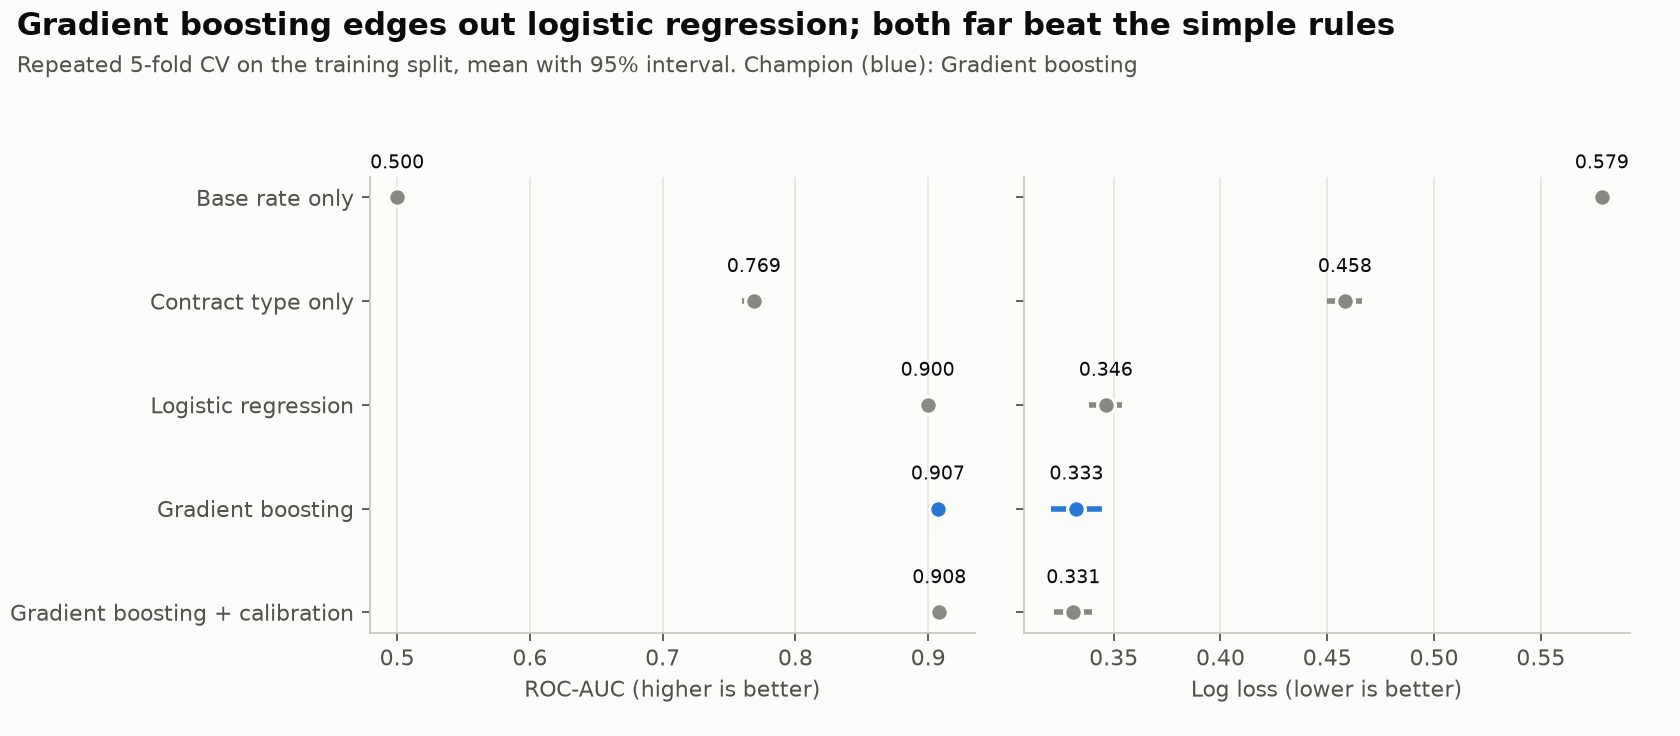

In [2]:
comparison = pd.read_csv("outputs/model_comparison.csv")
cols = ["model", "roc_auc_mean", "pr_auc_mean", "brier_skill_mean", "log_loss_mean", "ece_mean"]
display(comparison[cols].round(3))
Image("outputs/figures/04_model_comparison.png")

In [3]:
row = comparison.set_index("model")
display(Markdown(f"""
- The one-feature rule (contract type only) already reaches AUC **{row.loc['contract_only', 'roc_auc_mean']:.3f}**; the full models reach **{row.loc['logistic', 'roc_auc_mean']:.3f}** (logistic) and **{row.loc['hist_gb', 'roc_auc_mean']:.3f}** (gradient boosting).
- Selection metric is **log loss** because it rewards calibrated probabilities. Champion: **{champion_name}** ({metrics['selection_rationale']}).
- Gradient boosting has {row.loc['logistic', 'log_loss_mean'] - row.loc['hist_gb', 'log_loss_mean']:.3f} lower log loss than the logistic regression, which is outside the best model's one-standard-error band, so the edge is more than noise. It is modest in AUC terms ({row.loc['hist_gb', 'roc_auc_mean'] - row.loc['logistic', 'roc_auc_mean']:+.3f}), so the logistic regression stays a credible, more interpretable fallback.
"""))


- The one-feature rule (contract type only) already reaches AUC **0.769**; the full models reach **0.900** (logistic) and **0.907** (gradient boosting).
- Selection metric is **log loss** because it rewards calibrated probabilities. Champion: **hist_gb** (simplest model within 1 SE of the best (hist_gb_calibrated) on log_loss).
- Gradient boosting has 0.014 lower log loss than the logistic regression, which is outside the best model's one-standard-error band, so the edge is more than noise. It is modest in AUC terms (+0.008), so the logistic regression stays a credible, more interpretable fallback.


## 2. Honest evaluation on the untouched test set

Reproducing the headline in a few lines, so the number is not a black box:

In [4]:
loader = TelcoDataLoader(config)
df = loader.run()
train, test = loader.split(df)
X_train, numeric, categorical = prepare_features(train, config)
X_test, _, _ = prepare_features(test, config)

model = clone(build_candidates(config, numeric, categorical)[champion_name]).fit(X_train, train.churn)
proba = model.predict_proba(X_test)[:, 1]
pd.Series(evaluate_predictions(test.churn, proba)).round(4).to_frame("test set")

,test set
roc_auc,0.9106
pr_auc,0.7878
brier_score,0.1049
brier_skill,0.4621
log_loss,0.3279
ece,0.0199


In [5]:
h, ci = summary["model"]["holdout"], summary["model"]["holdout_ci"]
b = summary["model"]["baselines"]
display(Markdown(f"""
| | ROC-AUC | PR-AUC | Brier skill | ECE |
|---|---|---|---|---|
| **{champion_name}** | **{h['roc_auc']:.3f}** (95% CI {ci['roc_auc'][0]:.3f} to {ci['roc_auc'][1]:.3f}) | {h['pr_auc']:.3f} | {h['brier_skill']:.2f} | {h['ece']:.3f} |
| contract type only | {b['contract_only']['roc_auc']:.3f} | {b['contract_only']['pr_auc']:.3f} | {b['contract_only']['brier_skill']:.2f} | {b['contract_only']['ece']:.3f} |
| base rate for everyone | {b['prior']['roc_auc']:.3f} | {b['prior']['pr_auc']:.3f} | {b['prior']['brier_skill']:.2f} | {b['prior']['ece']:.3f} |

PR-AUC should be read against the base rate of {metrics['churn_rate']:.1%}, not against 0.5. Brier skill is the improvement over always predicting the base rate (0 = no skill, 1 = perfect).
"""))


| | ROC-AUC | PR-AUC | Brier skill | ECE |
|---|---|---|---|---|
| **hist_gb** | **0.911** (95% CI 0.895 to 0.927) | 0.788 | 0.46 | 0.020 |
| contract type only | 0.756 | 0.432 | 0.19 | 0.024 |
| base rate for everyone | 0.500 | 0.265 | -0.00 | 0.027 |

PR-AUC should be read against the base rate of 26.5%, not against 0.5. Brier skill is the improvement over always predicting the base rate (0 = no skill, 1 = perfect).


## 3. Calibration: why the model can be used in dollar math

A common shortcut for imbalanced classes is `class_weight="balanced"`. It lifts ranking sensitivity but inflates every predicted probability. Plotted against reality:

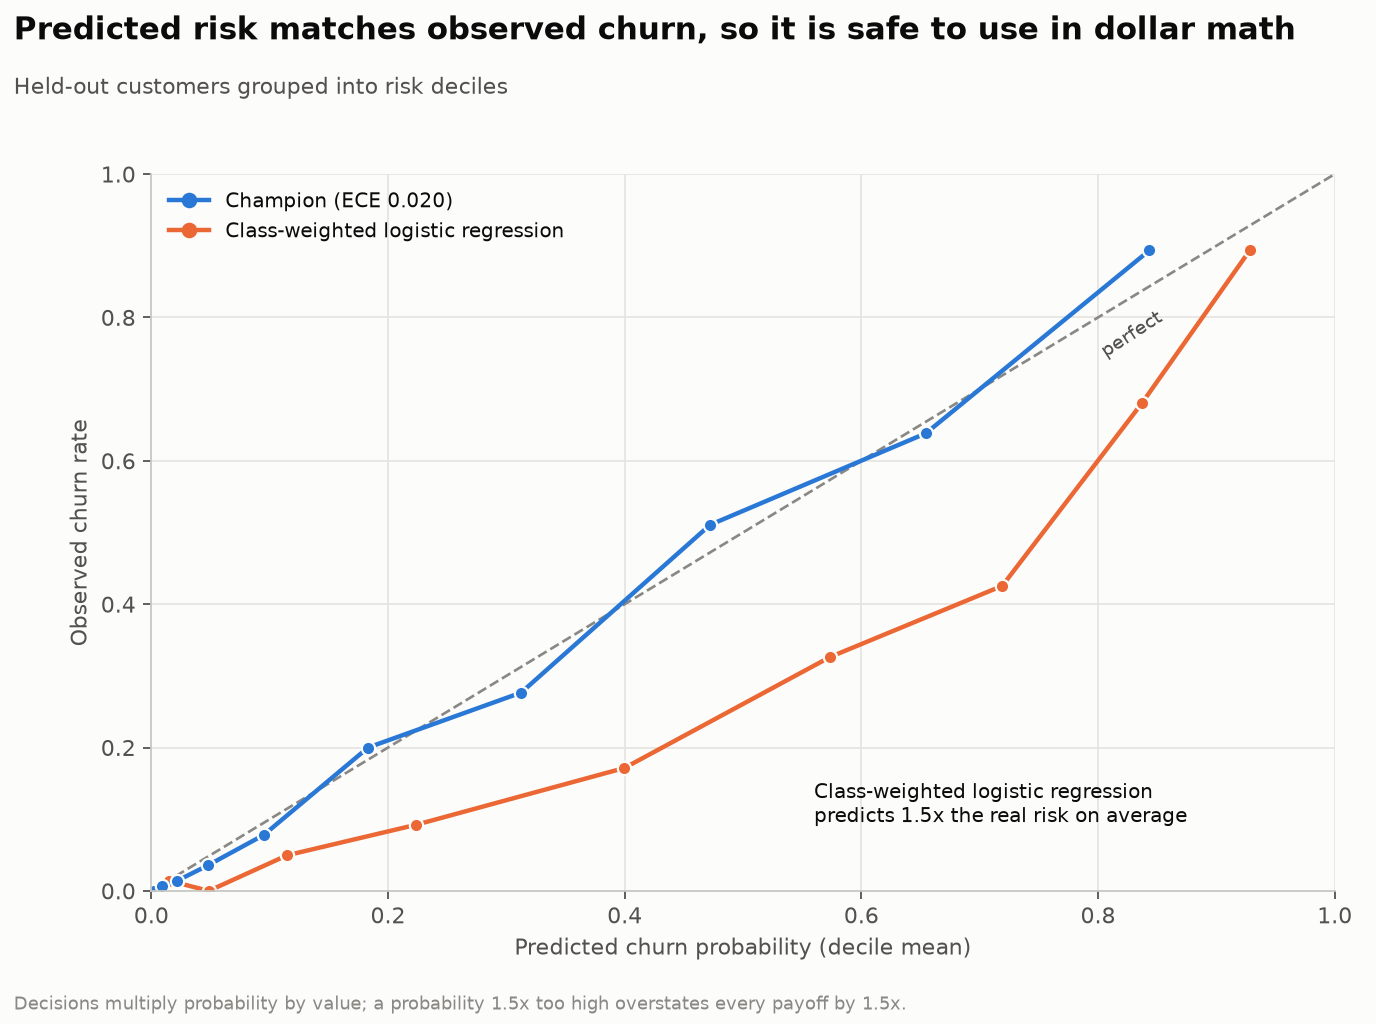


The class-weighted model predicts **1.5x the real churn risk on average**. Multiply that by customer value and every payoff is overstated by the same factor, and a "profitable" list can be unprofitable. (An earlier version of this project made this mistake at a much larger scale: its predicted probabilities averaged 18 times the true rate, and after calibration no customer had a positive expected value.) The champion here is trained without class weights and its calibration error is **0.020**.


In [6]:
display(Image("outputs/figures/05_calibration.png"))
factor = summary["model"]["class_weighted_overestimate_factor"]
display(Markdown(f"""
The class-weighted model predicts **{factor:.1f}x the real churn risk on average**. Multiply that by customer value and every payoff is overstated by the same factor, and a "profitable" list can be unprofitable. (An earlier version of this project made this mistake at a much larger scale: its predicted probabilities averaged 18 times the true rate, and after calibration no customer had a positive expected value.) The champion here is trained without class weights and its calibration error is **{h['ece']:.3f}**.
"""))

## 4. What drives churn

,term,odds_ratio,ci_low,ci_high,p_value,significant
0,Contract: Two Year (vs Month-to-Month),0.069,0.050,0.097,0.000,True
1,Dependents,0.235,0.187,0.294,0.000,True
2,Contract: One Year (vs Month-to-Month),0.253,0.205,0.313,0.000,True
3,Internet type: Cable (vs None),2.114,1.467,3.046,0.000,True
4,Senior citizen,2.067,1.724,2.478,0.000,True
5,Payment method: Mailed Check (vs Bank Withdrawal),1.859,1.403,2.463,0.000,True
6,Internet type: Fiber Optic (vs None),1.633,0.969,2.751,0.066,False
7,Payment method: Credit Card (vs Bank Withdrawal),0.626,0.536,0.731,0.000,True
8,Online security,0.627,0.525,0.750,0.000,True
9,Internet type: DSL (vs None),1.532,1.107,2.122,0.010,True


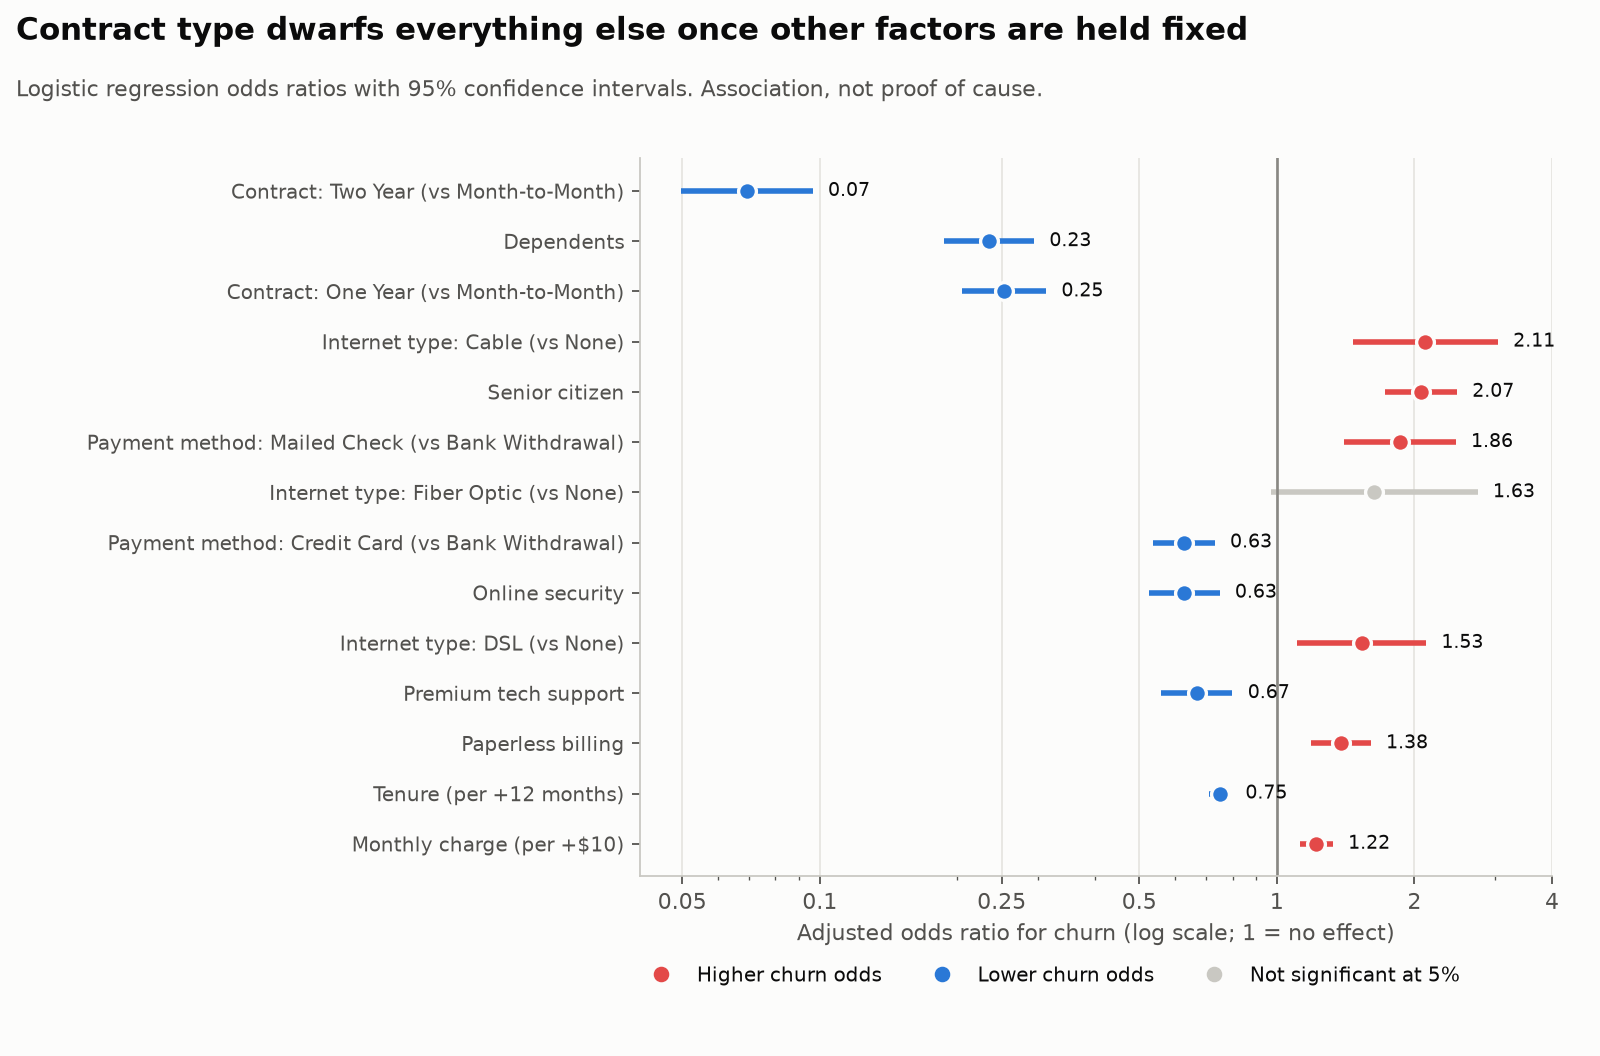

In [7]:
odds = pd.read_csv("outputs/odds_ratios.csv")
display(odds.head(10).round(3))
Image("outputs/figures/11_odds_ratios.png")

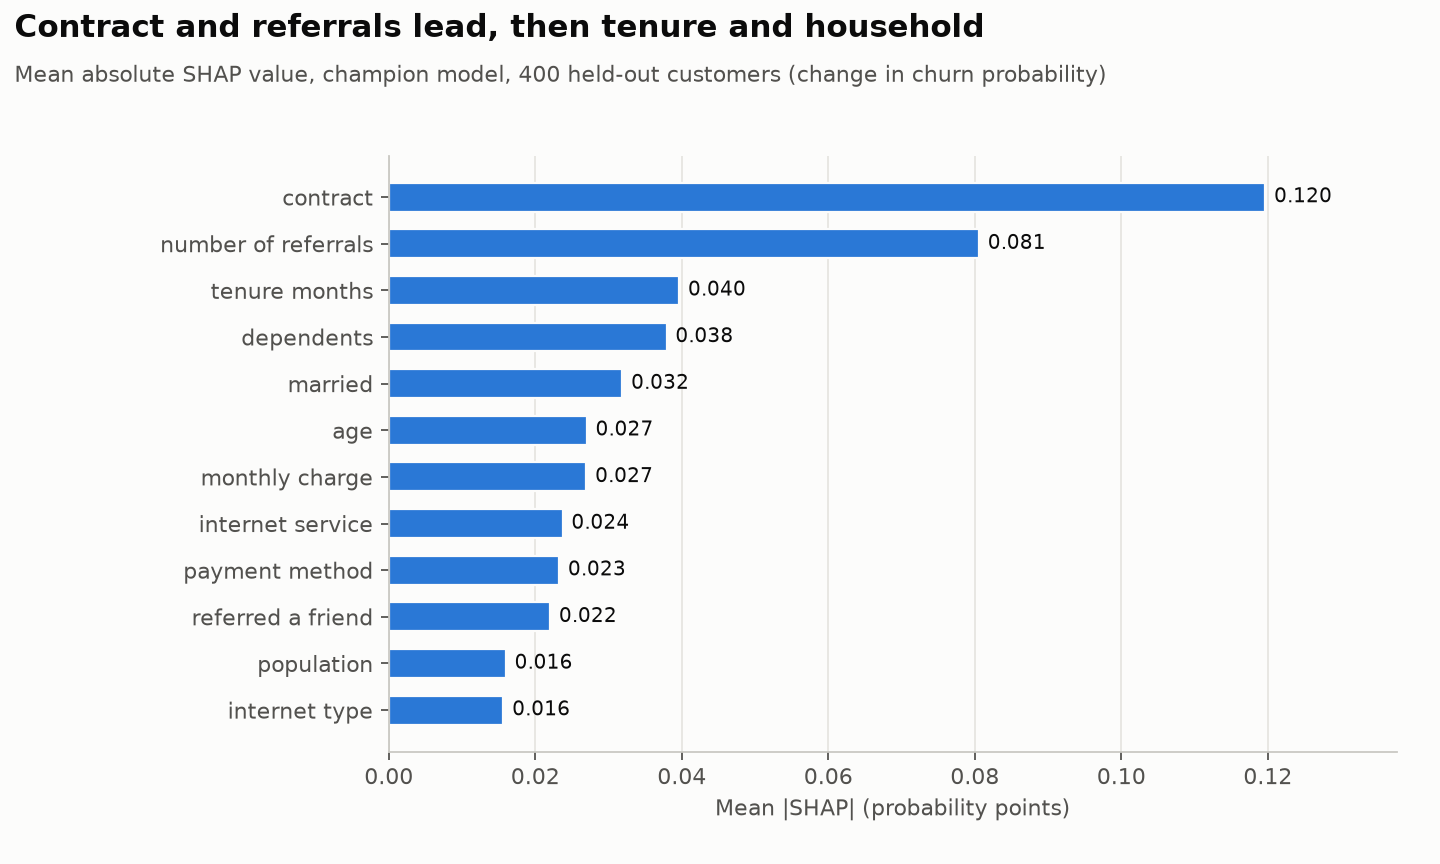

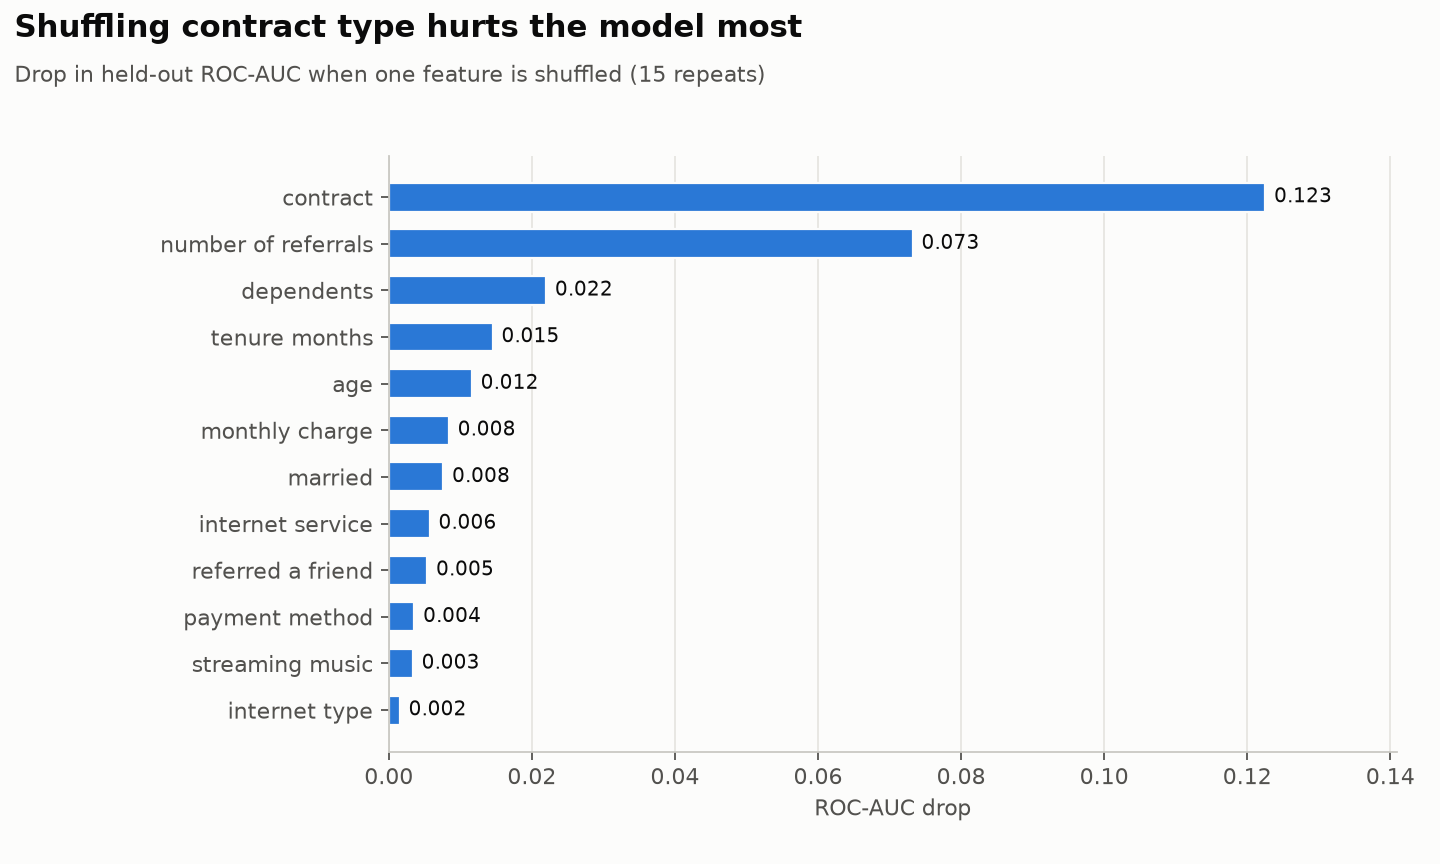

In [8]:
display(Image("outputs/figures/12_shap_importance.png"))
display(Image("outputs/figures/13_permutation_importance.png"))

Three independent views agree: **contract type** dominates. Two-year contracts cut the odds of churn by about 93% against month-to-month with other factors held fixed; dependents and tenure also protect; senior citizens and mailed-check payers churn more. Offers are deliberately excluded from the odds-ratio model because each offer is nearly a function of tenure band (notebook 01).

These are associations. None of them says that changing a customer's contract would change their churn.

## 5. From probability to decision

Contacting customer *i* has expected value

$$EV_i = p_i \cdot s \cdot V_i - c$$

where $p_i$ is the calibrated churn probability, $s$ the **save rate** (share of would-be churners who stay after contact), $V_i$ the margin kept if the customer is saved, and $c$ the contact cost. The cost is paid for every contact, so wasted offers to customers who would have stayed are already priced in. The assumptions:

In [9]:
a = decision["assumptions"]
pd.DataFrame(
    {
        "assumption": ["Save rate", "Cost per contact", "Gross margin", "Months of margin kept", "Monthly discount rate", "Campaign budget"],
        "value": [f"{a['save_rate']:.0%}", f"${a['cost_per_contact']:.0f}", f"{a['gross_margin']:.0%}", a["horizon_months"], f"{a['monthly_discount_rate']:.0%}", f"${decision['budget']['max_campaign_budget']:,.0f}"],
    }
).set_index("assumption")

,value
assumption,
Save rate,30%
Cost per contact,$25
Gross margin,40%
Months of margin kept,12
Monthly discount rate,1%
Campaign budget,"$20,000"



**Every dollar figure below rests on these assumptions, not on observed campaign results.**

- The \$20,000 budget buys **800 contacts**. Expected net profit **\$59,442** (ROI = net / cost = **297%**). Backtested against what customers actually did: **\$62,305**, so the expected and realized figures agree to within 5%.
- Bootstrap 95% interval for the realized figure: \$59,656 to \$65,009.
- With no budget limit the profit-maximizing list has **2,440 contacts** and expected net **\$100,809**.
- **Break-even save rate: 7.6%.** The campaign still pays for itself if only about 8% of would-be churners are saved, far below the assumed 30%.


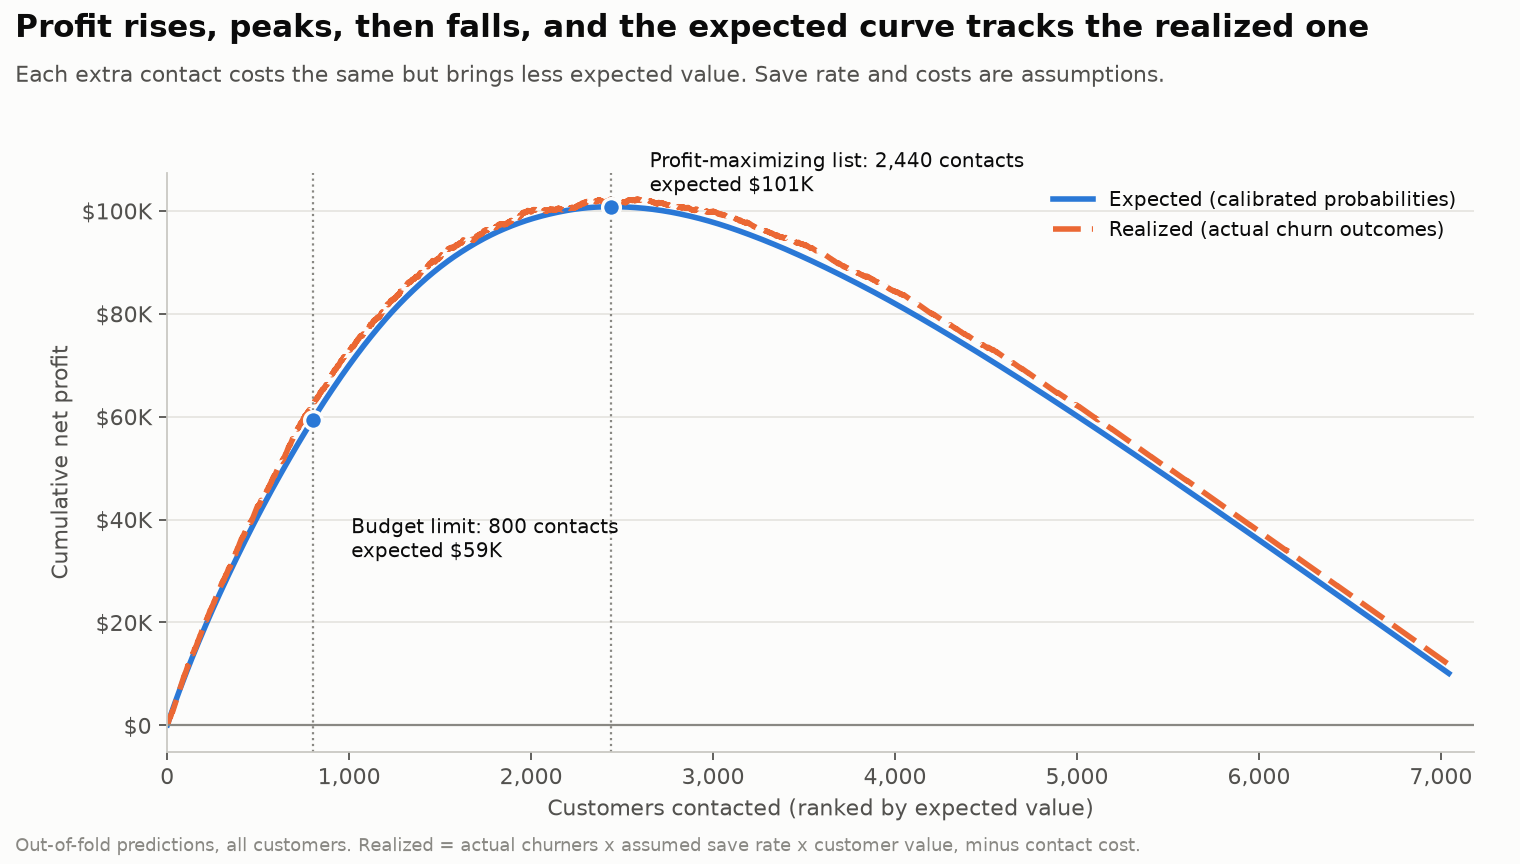

In [10]:
r, p = decision["recommended"], decision["profit_maximizing"]
display(Markdown(f"""
**Every dollar figure below rests on these assumptions, not on observed campaign results.**

- The {usd(decision['budget']['max_campaign_budget'])} budget buys **{r['contacts']:,} contacts**. Expected net profit **{usd(r['expected_net'])}** (ROI = net / cost = **{r['expected_roi']:.0%}**). Backtested against what customers actually did: **{usd(r['realized_net'])}**, so the expected and realized figures agree to within {abs(r['realized_net']/r['expected_net']-1):.0%}.
- Bootstrap 95% interval for the realized figure: {usd(r['bootstrap_realized_net']['lower'])} to {usd(r['bootstrap_realized_net']['upper'])}.
- With no budget limit the profit-maximizing list has **{p['contacts']:,} contacts** and expected net **{usd(p['expected_net'])}**.
- **Break-even save rate: {r['breakeven_save_rate']:.1%}.** The campaign still pays for itself if only about {r['breakeven_save_rate']:.0%} of would-be churners are saved, far below the assumed {a['save_rate']:.0%}.
"""))
display(Image("outputs/figures/07_profit_curve.png"))

,policy,contacts,cost,net,roi,precision,share_of_churners_reached
0,Model: rank by expected value,800,20000.0,62304.71,3.12,0.85,0.36
1,Model: rank by churn probability,800,20000.0,57409.23,2.87,0.88,0.38
2,Rule: Month-to-Month + Fiber Optic,800,20000.0,33285.25,1.66,0.57,0.24
3,Random contacts,800,20000.0,1244.04,0.06,0.26,0.11


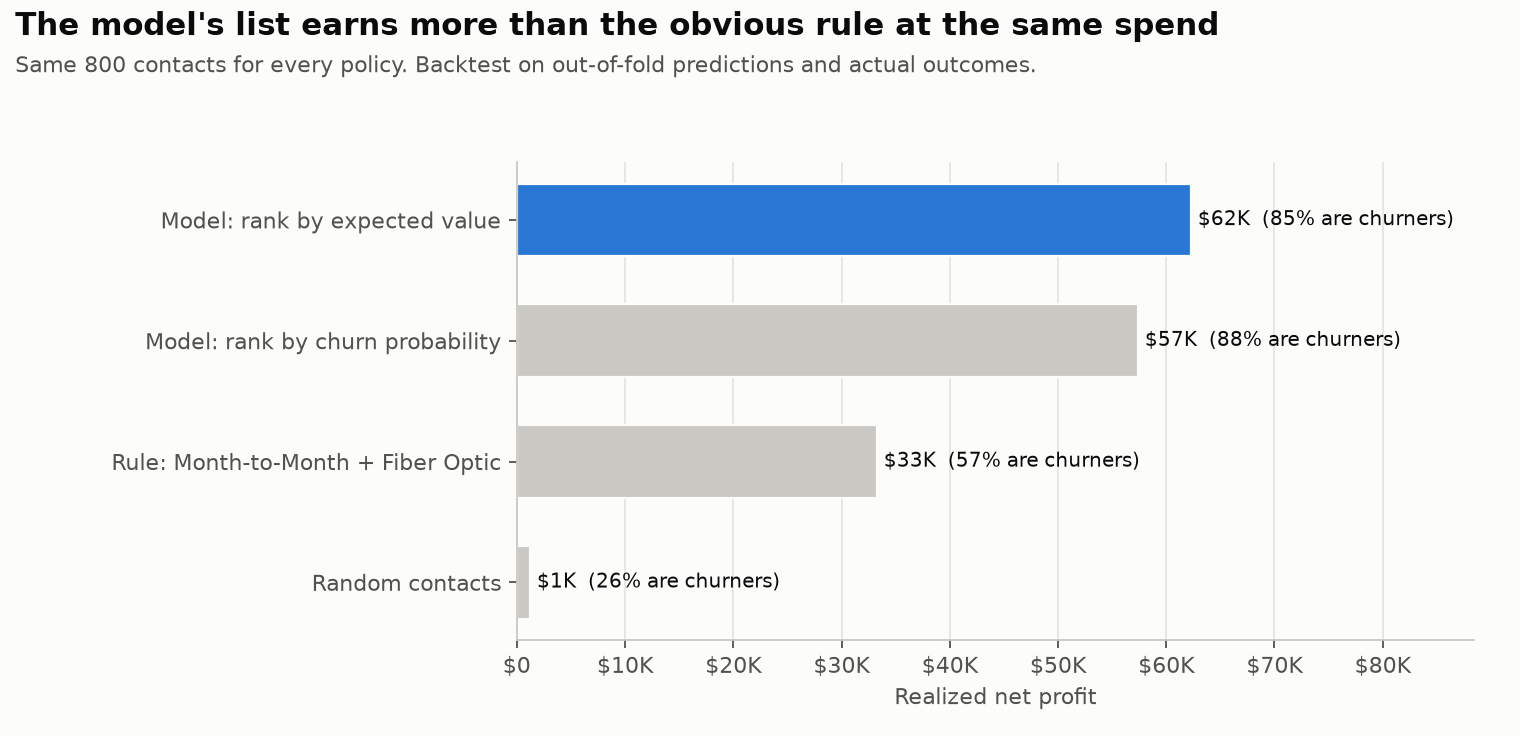

At the same 800 contacts the model's list earns **1.9x** what the month-to-month-fiber rule earns, and the rule reaches fewer churners per contact. Contacting at random roughly breaks even, which is why a ranking is worth building.

In [11]:
policies = pd.DataFrame(decision["policies"])[["policy", "contacts", "cost", "net", "roi", "precision", "share_of_churners_reached"]]
display(policies.round(2))
display(Image("outputs/figures/08_policy_comparison.png"))
display(Markdown(f"At the same {r['contacts']:,} contacts the model's list earns **{r['model_vs_rule_net_ratio']:.1f}x** what the month-to-month-fiber rule earns, and the rule reaches fewer churners per contact. Contacting at random roughly breaks even, which is why a ranking is worth building."))

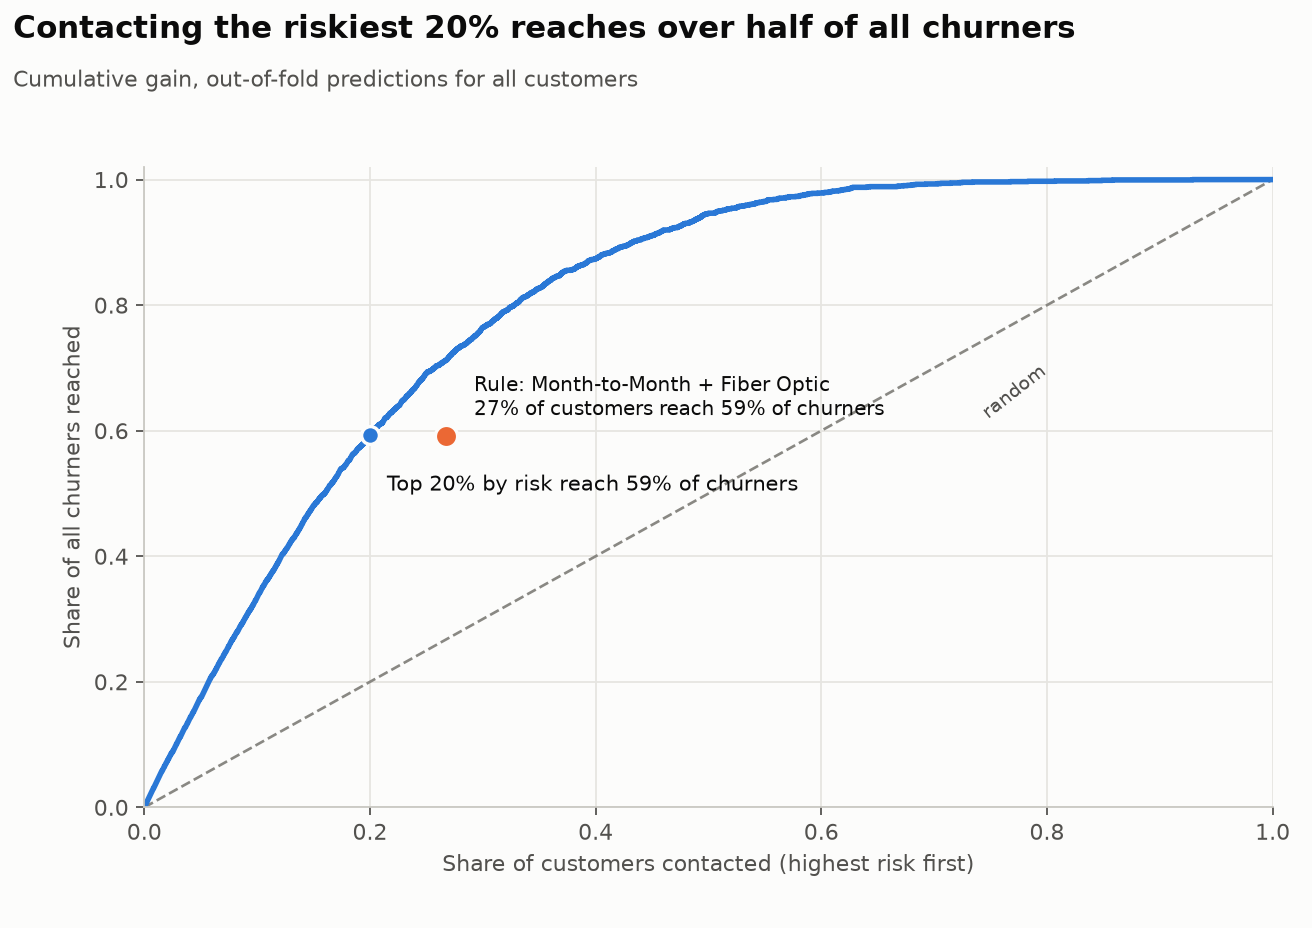

In [12]:
display(Image("outputs/figures/06_gain_curve.png"))

## 6. How much do the assumptions matter?

The save rate is unobserved, so the conclusion should not depend on a single guess. Left: best profit within the budget across save rates and contact costs. Right: each assumption moved alone.

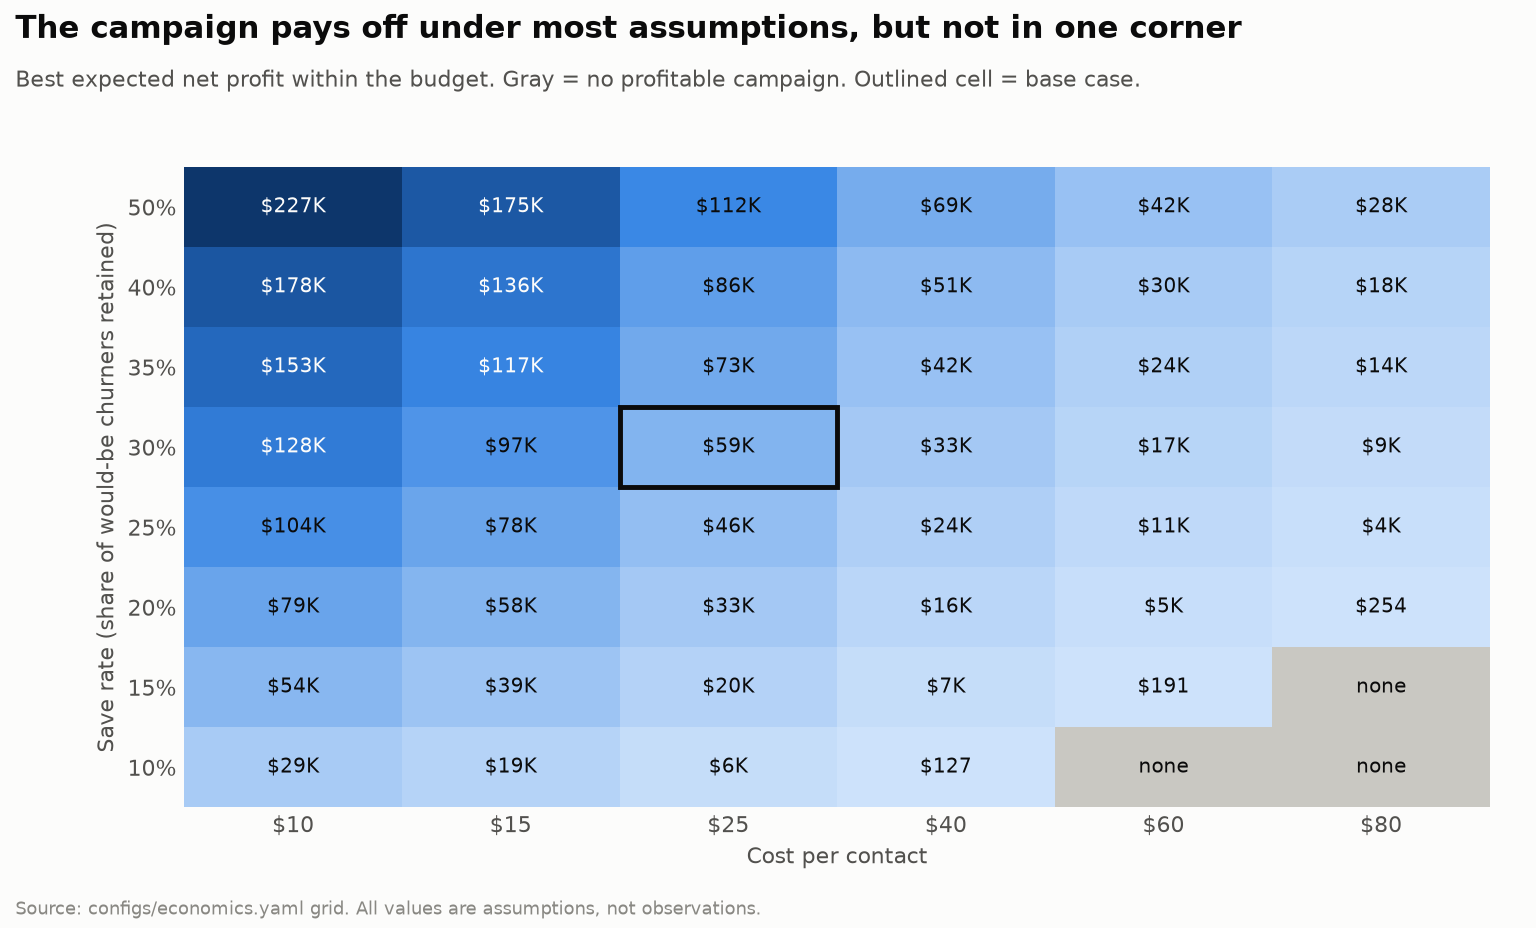

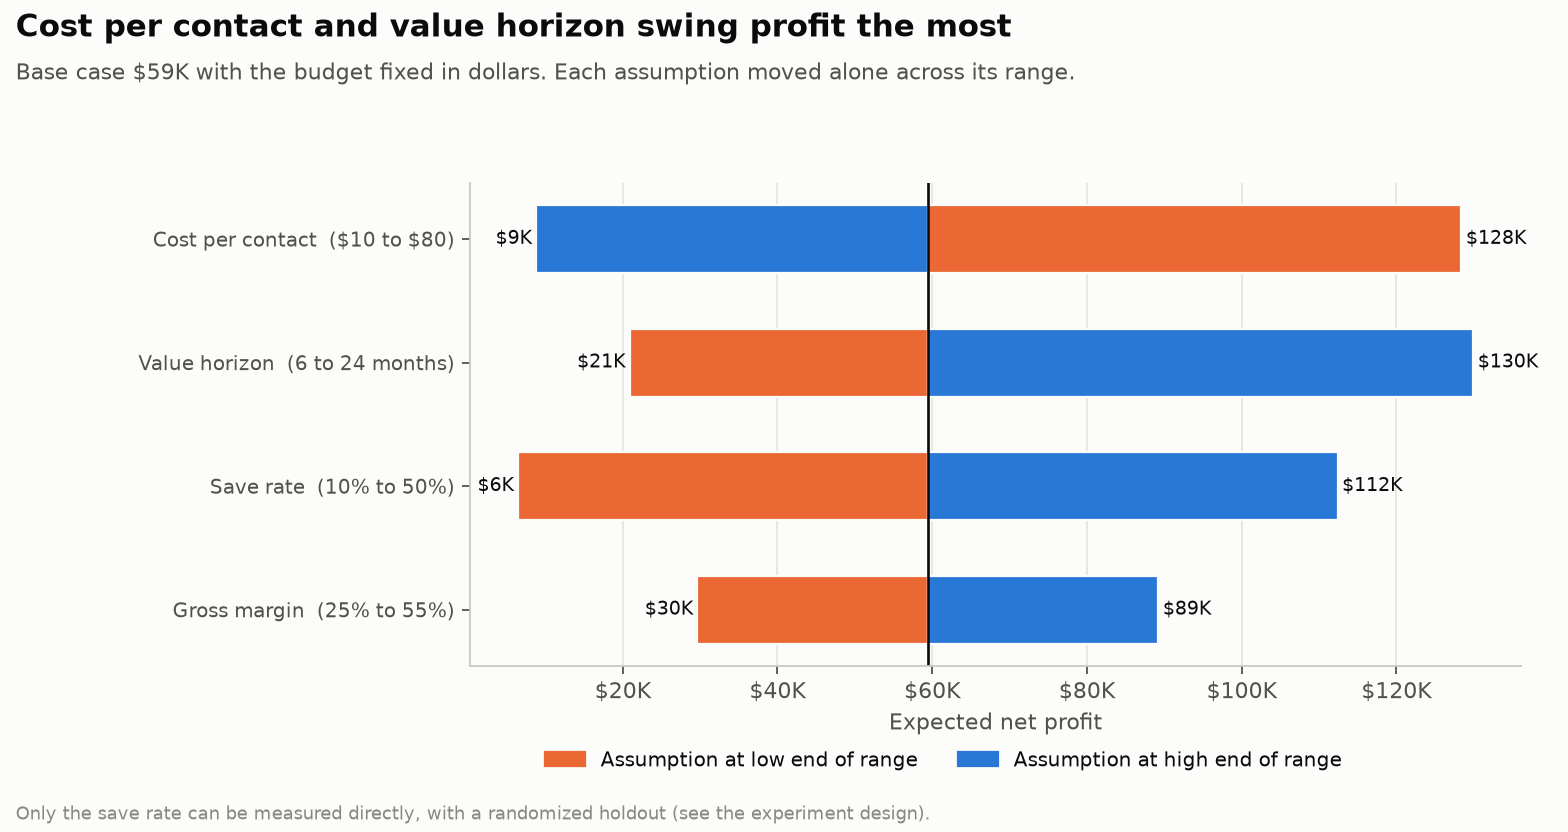

In [13]:
display(Image("outputs/figures/09_sensitivity_heatmap.png"))
display(Image("outputs/figures/10_tornado.png"))

## 7. Measuring the save rate: experiment design

The model says who. Only a randomized holdout says whether the offer works. This project has no campaign data, so it **designs** the test and does not report a result.

,save_rate,churn_if_untreated,churn_if_treated,detectable_difference,n_treatment,n_control,n_total,simulated_power
0,0.05,0.848,0.805,0.042,1251,1251,2502,0.808
1,0.10,0.848,0.763,0.085,340,340,680,0.800
2,0.15,0.848,0.720,0.127,162,162,324,0.796
3,0.20,0.848,0.678,0.170,96,96,192,0.796
4,0.30,0.848,0.593,0.254,47,47,94,0.804



- Among contacted customers the churn rate without an offer would be about **85%**.
- Detecting the break-even save rate (7.6%) with 80% power needs about **573 customers per arm** (1,146 total).
- The 800-contact budget list, split 50/50, can only detect a save rate of **9% or more**; to test smaller effects, run the holdout over several waves or the full profit-maximizing list.
- A Monte Carlo check of each design row gives simulated power between 0.80 and 0.81, matching the 0.80 target.


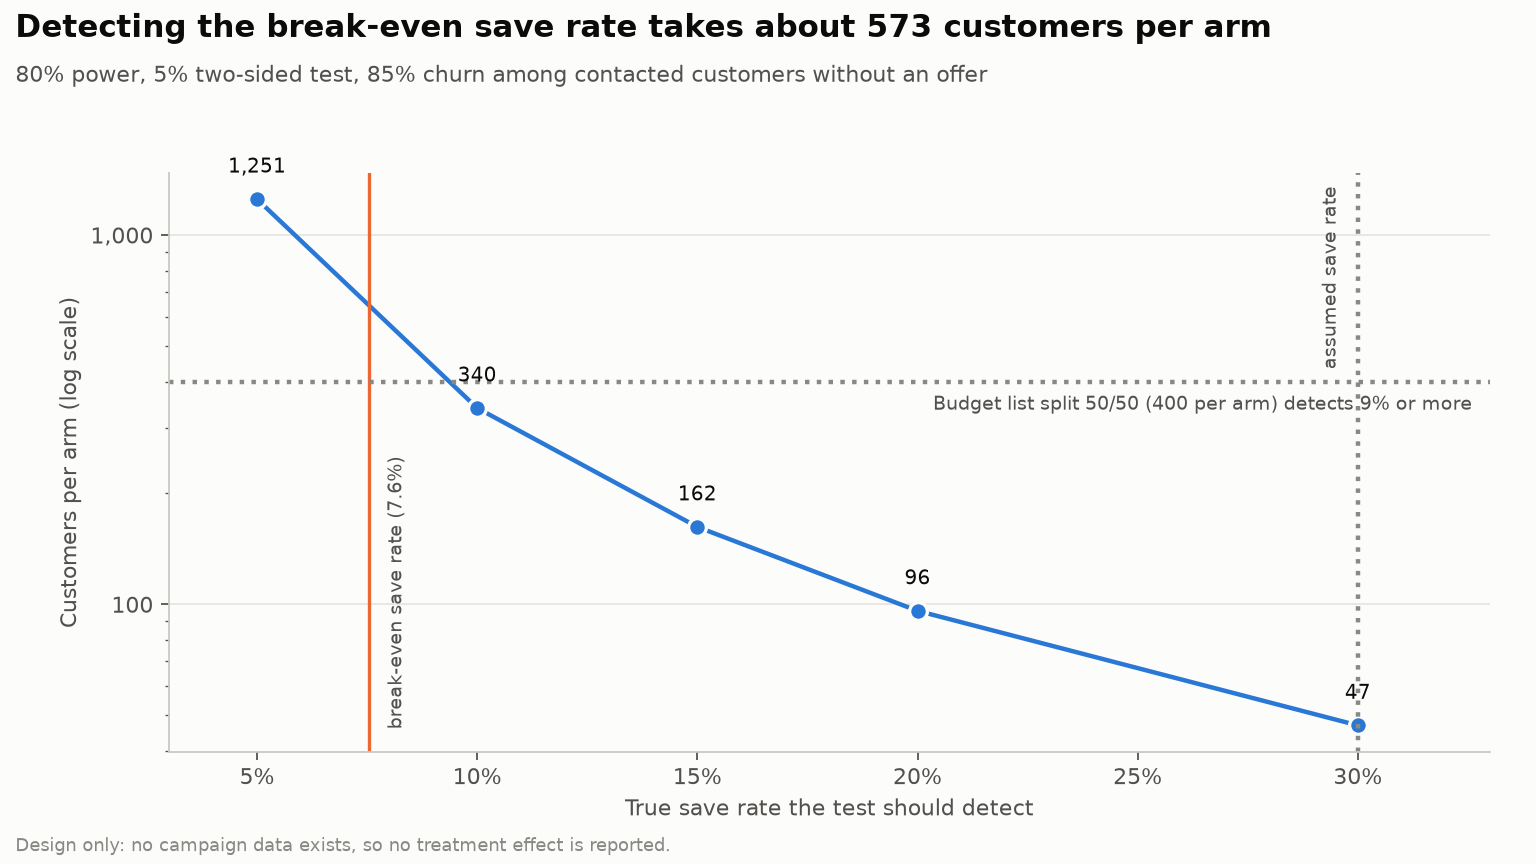

In [14]:
design = pd.read_csv("outputs/experiment_design.csv")
display(design.round(3))
display(Markdown(f"""
- Among contacted customers the churn rate without an offer would be about **{experiment['baseline_churn_rate_contacted']:.0%}**.
- Detecting the break-even save rate ({experiment['breakeven_save_rate']:.1%}) with 80% power needs about **{experiment['n_treatment_to_detect_breakeven']:,} customers per arm** ({experiment['n_total_to_detect_breakeven']:,} total).
- The {experiment['contacts_in_budget']:,}-contact budget list, split 50/50, can only detect a save rate of **{experiment['detectable_save_rate_with_budget_list']:.0%} or more**; to test smaller effects, run the holdout over several waves or the full profit-maximizing list.
- A Monte Carlo check of each design row gives simulated power between {experiment['simulated_power_min']:.2f} and {experiment['simulated_power_max']:.2f}, matching the 0.80 target.
"""))
Image("outputs/figures/14_experiment_power.png")

## Limitations and next steps

- **Dollar results are conditional on assumed save rate, cost, margin and horizon.** The sensitivity analysis bounds the conclusion; only an experiment removes the uncertainty.
- **No treatment data**, so the model ranks by churn risk, not by *persuadability*. A customer who will leave no matter what, or stay no matter what, is wasted spend. With experiment data the next step is an uplift model.
- **One quarter, no time axis**: cannot test drift or forecast a horizon.
- **Synthetic sample data**: nothing here describes real customers.
- Next: collect the holdout, estimate the true save rate, re-run `python run_pipeline.py --stage decide` with the measured value.